# California Housing Price Regression

**Task 2 | Regression | OLS, Ridge, and Lasso**

This notebook benchmarks three linear regression approaches on the local California housing dataset. It engineers household and location interaction features, imputes missing values, standardizes numeric inputs, encodes ocean proximity, and tunes Ridge/Lasso regularization with training-only cross-validation.

Evaluation uses a held-out test set with RMSE, MAE, and R², plus predicted-versus-actual and residual plots. The benchmark is reproducible and makes no network or API calls.

## 1. Setup and reproducibility

Open this notebook from the project directory or a child directory. The reusable training and plotting implementation is in `housing_regression.py`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next((path for path in candidate_roots if (path / 'data.csv').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Could not locate data.csv. Open this notebook from the Estate project folder.')
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from housing_regression import (
    DEFAULT_ALPHAS,
    TARGET_COLUMN,
    engineer_features,
    load_housing_data,
    plot_correlation_heatmap,
    plot_target_distribution,
    run_benchmark,
    split_dataset,
)

DATA_PATH = PROJECT_DIR / 'data.csv'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
print(f'Project: {PROJECT_DIR.name}')
print(f'Dataset: {DATA_PATH.name}')

Project: Estate
Dataset: data.csv


## 2. Load and inspect the supplied data

The housing data has 20,640 records, a continuous median house value target, numeric measurements, and the categorical `ocean_proximity` feature. Missing feature values are allowed and will be imputed inside the model pipeline; target values are required.

In [2]:
data = load_housing_data(DATA_PATH)
display(data.head())
print(f'Rows: {len(data):,} | Columns: {data.shape[1]}')
print(f'Exact duplicate rows: {data.duplicated().sum():,}')
display(data.dtypes.rename('dtype').to_frame())
display(data.isna().sum().rename('missing values').to_frame())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Rows: 20,640 | Columns: 10
Exact duplicate rows: 0


,dtype
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,string


,missing values
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [3]:
print('Ocean proximity categories:')
display(data['ocean_proximity'].value_counts(dropna=False).rename('districts').to_frame())
print('Target distribution:')
display(data[TARGET_COLUMN].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame())
target_max = data[TARGET_COLUMN].max()
at_ceiling = int((data[TARGET_COLUMN] == target_max).sum())
print(f'Observed target maximum: ${target_max:,.0f} ({at_ceiling:,} records at that value)')

Ocean proximity categories:


,districts
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


Target distribution:


,median_house_value
count,20640.000000
mean,206855.816909
std,115395.615874
min,14999.000000
50%,179700.000000
90%,376600.000000
95%,489810.000000
99%,500001.000000
max,500001.000000


Observed target maximum: $500,001 (965 records at that value)


> **Target cap caveat:** the supplied file has an observed maximum of $500,001, and many records equal that value. This is a cap in the dataset, not evidence that these homes all have the same true market value. Regression errors for high-value homes may be affected by this censored target.

## 3. Exploratory analysis

The target is strongly right-skewed and capped at its observed maximum. The heatmap includes original numeric variables, engineered features, and the target. Correlated inputs motivate comparing regularized estimators with OLS; correlation alone is not used as a feature-selection rule.

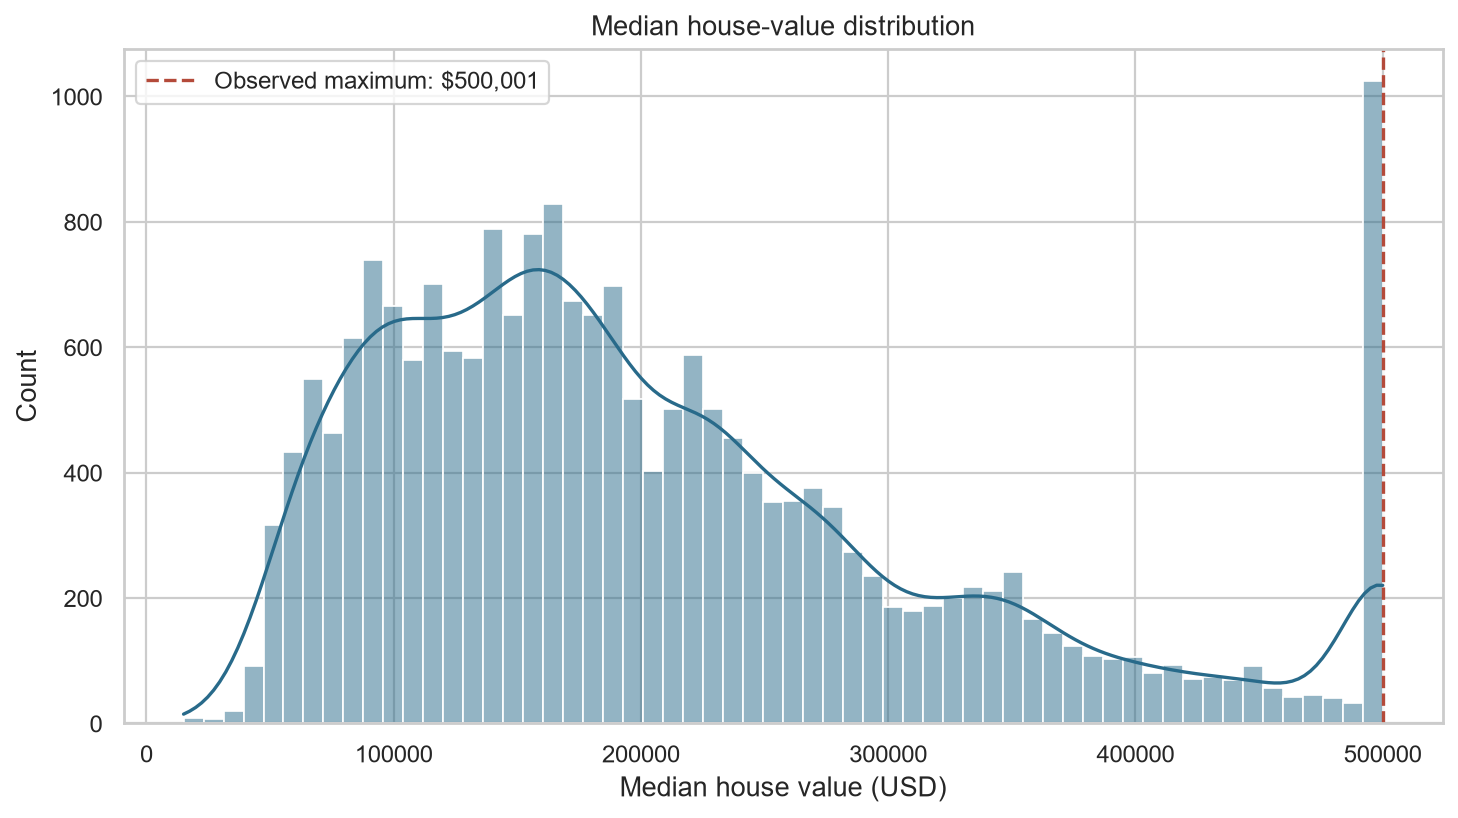

In [4]:
target_distribution_path = plot_target_distribution(data, OUTPUT_DIR)
display(Image(filename=str(target_distribution_path)))

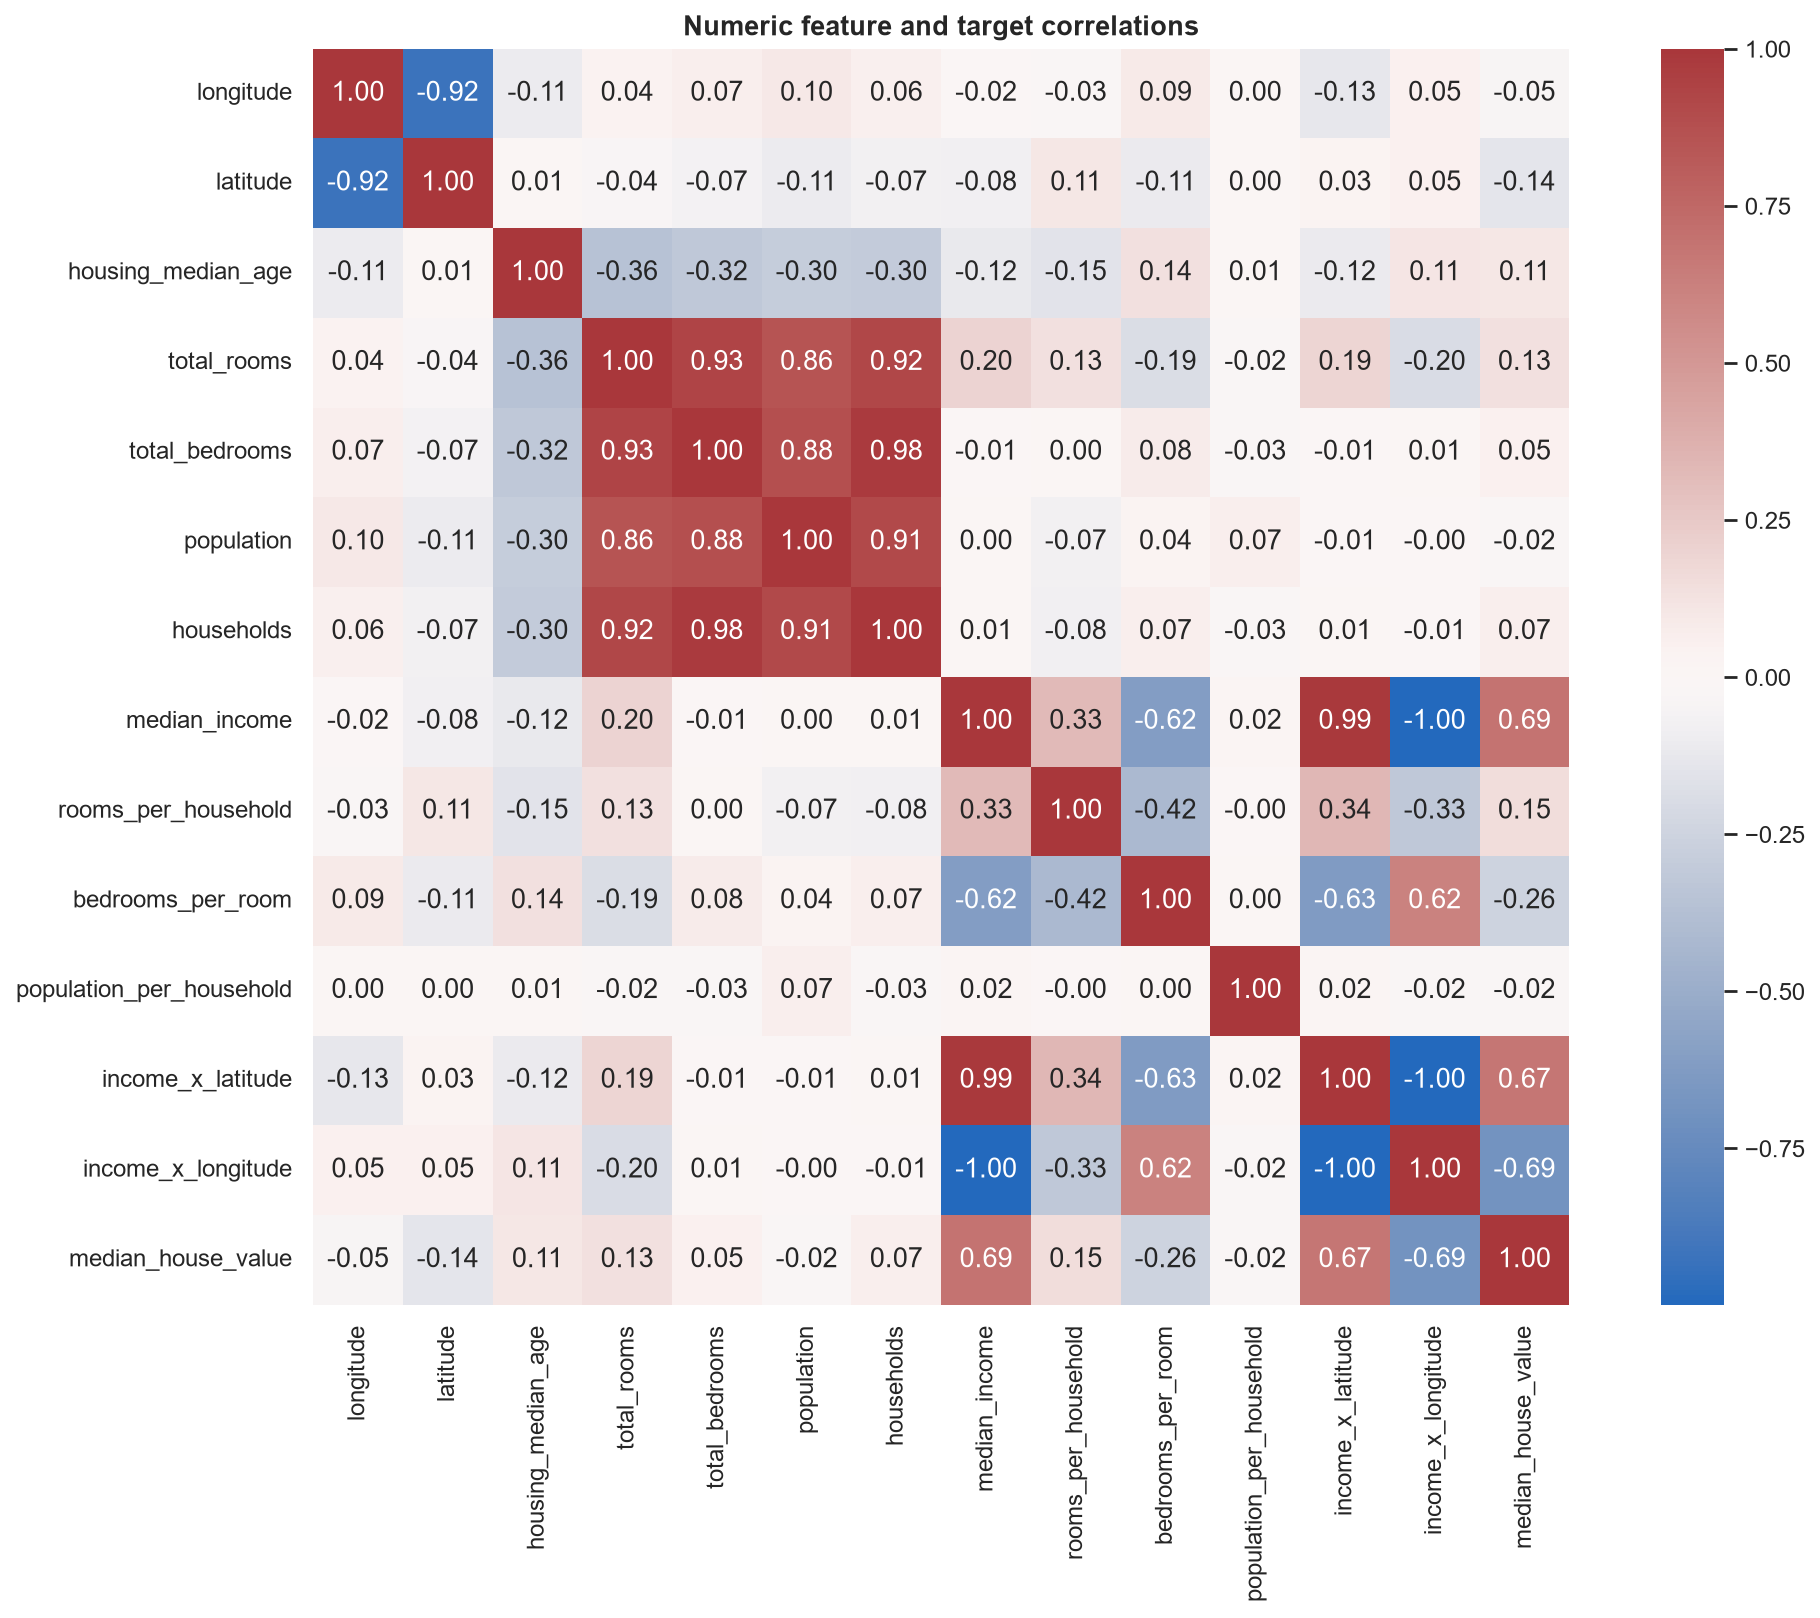

In [5]:
correlation_path = plot_correlation_heatmap(data, OUTPUT_DIR)
display(Image(filename=str(correlation_path)))

## 4. Feature engineering and preprocessing

Stateless transformations add rooms per household, bedrooms per room, population per household, and median-income-by-coordinate interactions. Division by zero yields a missing derived feature, which is handled by the numeric imputer. Missing `total_bedrooms` also propagates to its ratio and is imputed using training-fold medians.

The pipeline standardizes numeric features and one-hot encodes `ocean_proximity` while dropping one reference category. Imputers and scalers are fitted within each training fold, preventing information from the holdout or validation fold from leaking into preprocessing.

In [6]:
engineered_preview = engineer_features(data.drop(columns=[TARGET_COLUMN]))
display(engineered_preview.head())
print('Engineered feature count:', engineered_preview.shape[1] - (data.shape[1] - 1))

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_x_latitude,income_x_longitude
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY,6.984127,0.146591,2.555556,315.358576,-1017.589196
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY,6.238137,0.155797,2.109842,314.291004,-1014.597108
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY,8.288136,0.129516,2.802260,274.692590,-887.144576
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY,5.817352,0.184458,2.547945,213.591335,-689.868975
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY,6.281853,0.172096,2.181467,145.578670,-470.197950


Engineered feature count: 5


## 5. Holdout split

An 80/20 random split with seed 42 is created before fitting preprocessing. The 4,128-row test set is held out from Ridge/Lasso alpha selection and used only for the final model comparison.

In [7]:
X_train, X_test, y_train, y_test = split_dataset(data)
print(f'Train rows: {len(X_train):,} | Test rows: {len(X_test):,}')
print(f'Training target mean: ${y_train.mean():,.0f}')
print(f'Test target mean: ${y_test.mean():,.0f}')

Train rows: 16,512 | Test rows: 4,128
Training target mean: $207,195
Test target mean: $205,500


## 6. OLS, Ridge, and Lasso model selection

OLS is fitted as the unregularized baseline. Ridge and Lasso are each tuned with five-fold `GridSearchCV`, minimizing RMSE over the alpha grid below. For stable alpha scales, Ridge/Lasso standardize the target inside `TransformedTargetRegressor`; predictions and scores are inverse-transformed back to dollars. All data-dependent preprocessing is inside each searched pipeline. `n_jobs=1` is used for predictable memory use on the full dataset.

In [8]:
ALPHAS = DEFAULT_ALPHAS
CV_FOLDS = 5
print('Alpha candidates:', ALPHAS)
print('CV folds:', CV_FOLDS)
benchmark = run_benchmark(DATA_PATH, OUTPUT_DIR, cv=CV_FOLDS, alphas=ALPHAS)
summary = benchmark['summary']
results = benchmark['results']
cv_results = benchmark['cv_results']

Alpha candidates: (0.001, 0.002, 0.005, 0.01, 0.02)
CV folds: 5


## 7. Holdout performance

RMSE penalizes larger errors more heavily, MAE gives the typical absolute error in dollars, and R² reports the fraction of target variance explained relative to predicting the test-set mean. R² can be negative if a model performs worse than that baseline.

In [9]:
display(summary.set_index('model').round(3))

,rmse,mae,r2,cv_rmse,best_alpha,nonzero_coefficients
model,,,,,,
OLS,68679.613,49133.691,0.640,NaN,NaN,17
Ridge,68687.334,49144.610,0.640,67584.677,0.010,17
Lasso,69151.100,49621.148,0.635,67865.087,0.001,15


### Cross-validation results

The table reports training-fold mean and standard deviation of RMSE for each candidate alpha. The selected value is based on mean cross-validation RMSE, not the held-out test score.

In [10]:
display(cv_results.pivot(index='alpha', columns='model', values='cv_rmse_mean').round(2))
display(summary.set_index('model')[['best_alpha', 'nonzero_coefficients']])

model,Lasso,Ridge
alpha,,
0.001,67865.09,67585.52
0.002,67869.17,67585.37
0.005,67958.82,67585.02
0.010,68416.55,67584.68
0.020,70108.89,67584.80


,best_alpha,nonzero_coefficients
model,,
OLS,NaN,17
Ridge,0.010,17
Lasso,0.001,15


## 8. Predicted versus actual values

Points close to the dashed identity line indicate accurate predictions. The upper horizontal band reflects the capped target values; models cannot learn the uncensored values from those rows.

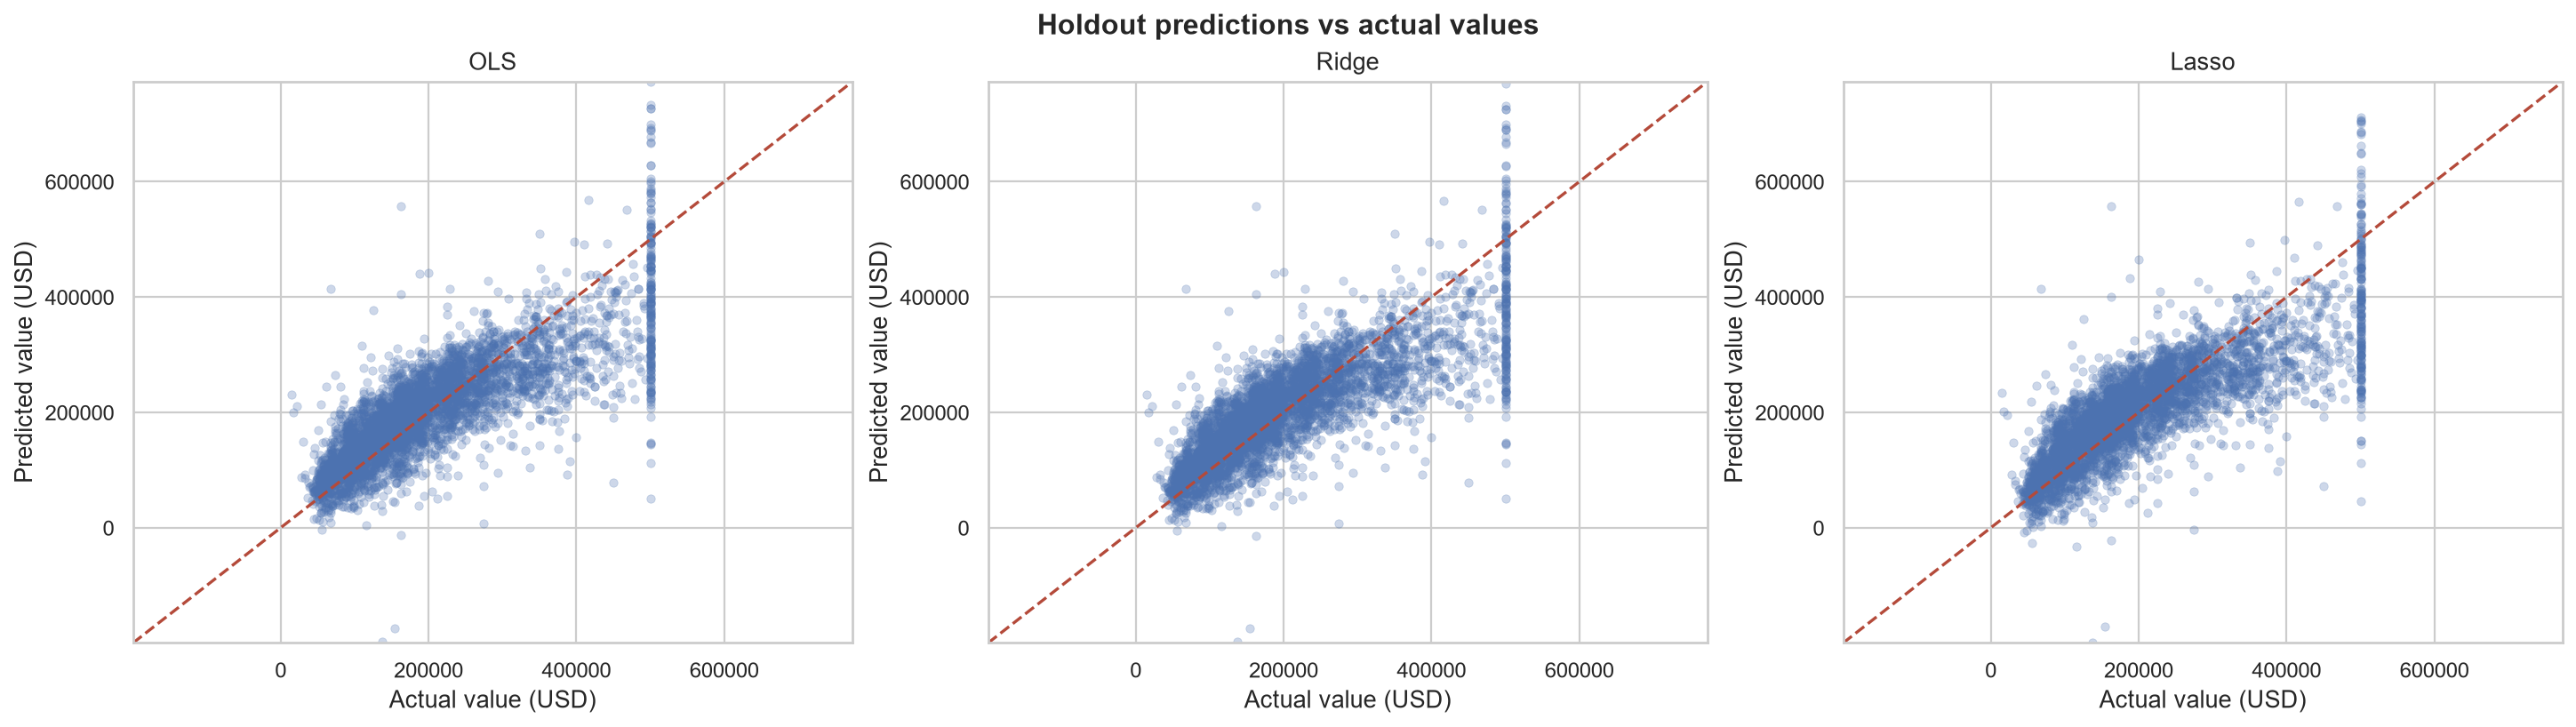

In [11]:
display(Image(filename=str(benchmark['artifacts']['predicted_vs_actual'])))

## 9. Residual analysis

Residuals are actual minus predicted. A well-behaved model should have residuals centered near zero without strong structure versus fitted values. Widening spread or visible patterns may indicate non-constant variance, nonlinearity, or missing predictors.

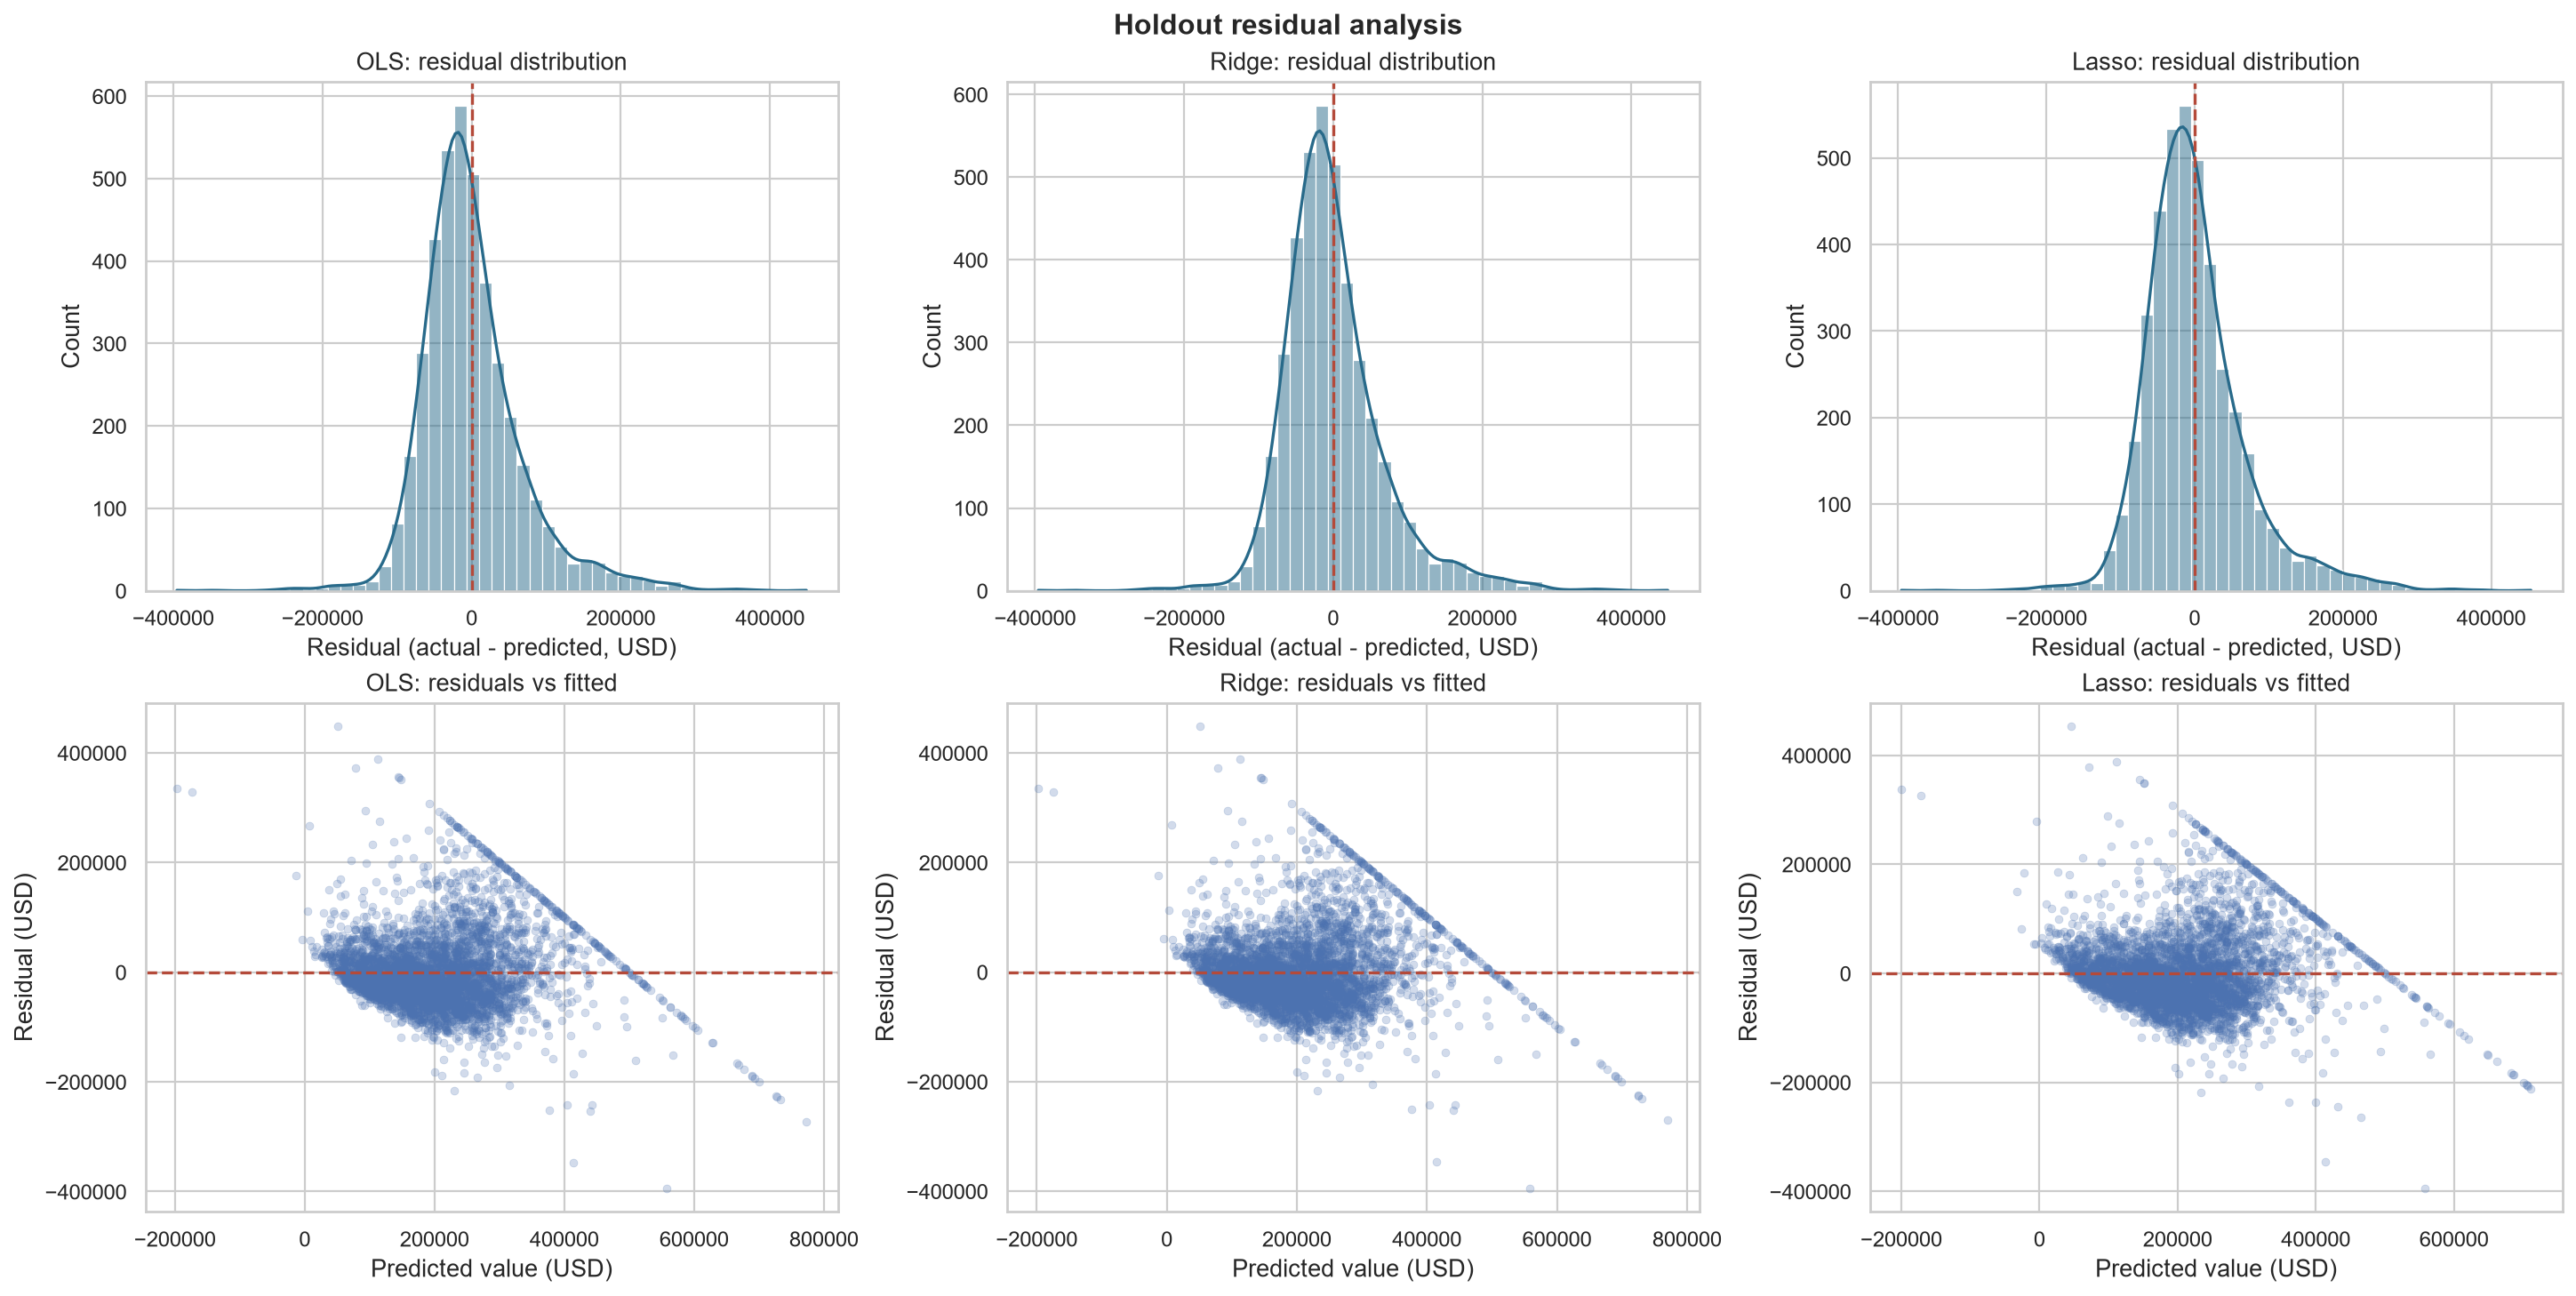

,mean_residual,median_residual,residual_std,within_50000_usd
OLS,572.756,-10127.829,68685.545,0.637
Ridge,579.581,-10079.995,68693.209,0.637
Lasso,799.982,-8812.313,69154.849,0.629


In [12]:
display(Image(filename=str(benchmark['artifacts']['residual_analysis'])))
display(pd.DataFrame(benchmark['residual_summary']).T.round(3))

## 10. Summary and saved deliverables

The outputs directory contains test-set metrics, every Ridge/Lasso CV candidate result, residual summary statistics, dataset/methodology metadata, and the generated charts. Re-run `python housing_regression.py` or execute this notebook to reproduce them.

This project is an educational benchmark rather than a production valuation model. It uses a random holdout from one historical dataset, and the high-value target cap limits interpretation at the expensive end. Geographic or time-based validation would be needed to assess generalization to new regions or future markets.

In [13]:
print('Artifacts:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f' - {path.name}')

Artifacts:
 - benchmark_metadata.json
 - correlation_heatmap.png
 - model_metrics.csv
 - predicted_vs_actual.png
 - regularization_cv_results.csv
 - residual_analysis.png
 - residual_summary.json
 - target_distribution.png
